# DMD, inflation sensitivity, and style overlap
These are existing **2.5% predicted TE** experiments, not the final 1% experiment. Historical residual DMD removes all four style controls; the final experiment below removes only the Barra pair. Returns are gross of costs. Active Sharpe means mean active return divided by active volatility, annualized (an information ratio).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
DATA = Path('dataset')
assert DATA.exists(), 'Run from the submission directory'
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top':False, 'axes.spines.right':False})


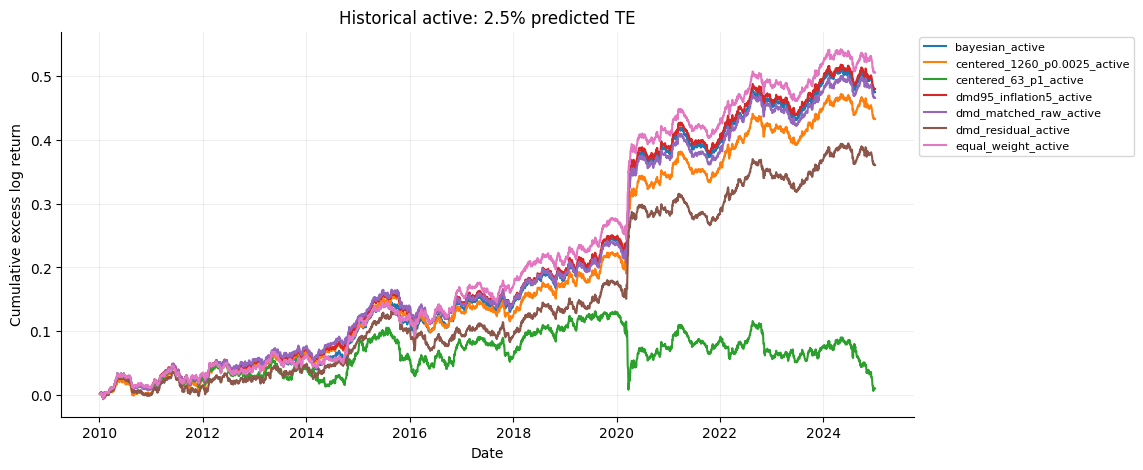

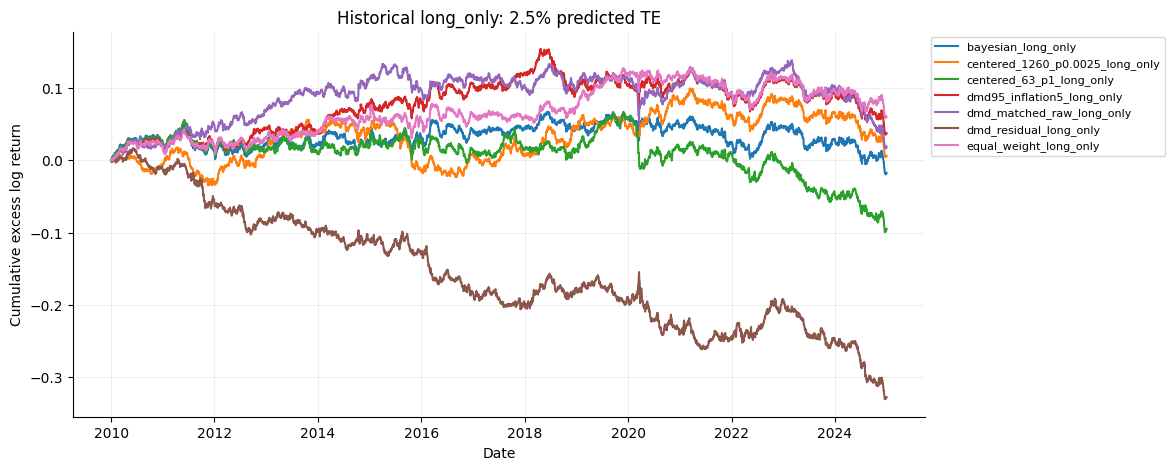

In [2]:
r = pd.concat([pd.read_parquet(DATA/'historical_candidates_returns.parquet'),pd.read_parquet(DATA/'historical_bma_returns.parquet')])
for variant in ['active','long_only']:
    fig, ax = plt.subplots()
    for name, g in r[r.portfolio.str.endswith('_'+variant)].groupby('portfolio'):
        g=g.sort_values('date')
        ax.plot(g.date, (np.log1p(g.portfolio_return)-np.log1p(g.benchmark_return)).cumsum(), label=name)
    ax.set(title=f'Historical {variant}: 2.5% predicted TE',ylabel='Cumulative excess log return',xlabel='Date')
    ax.legend(fontsize=8,loc='upper left',bbox_to_anchor=(1,1)); ax.grid(alpha=.2); plt.show()


## Original DMD versus style-residualized DMD
Matched raw DMD and residualized DMD use identical coverage. This isolates the removal of styles from changes to the sample.

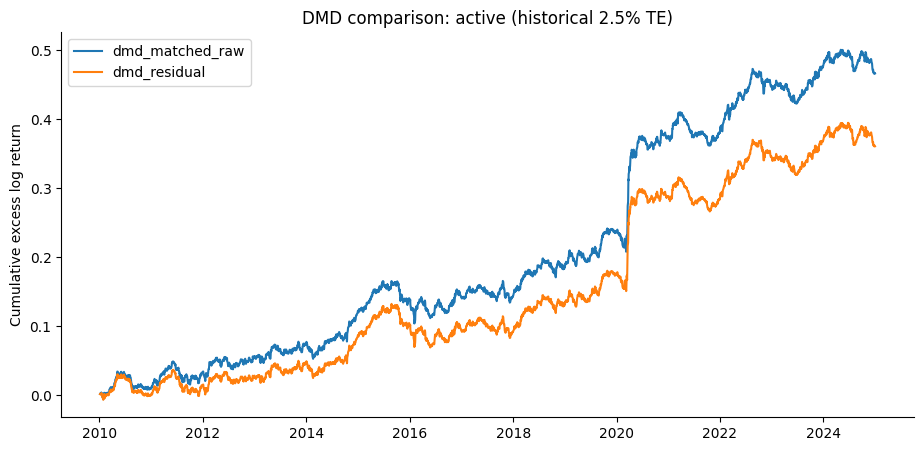

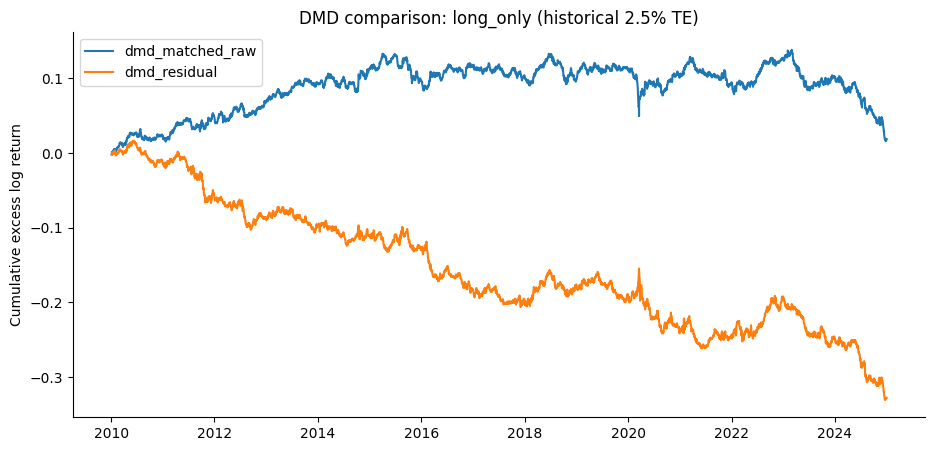

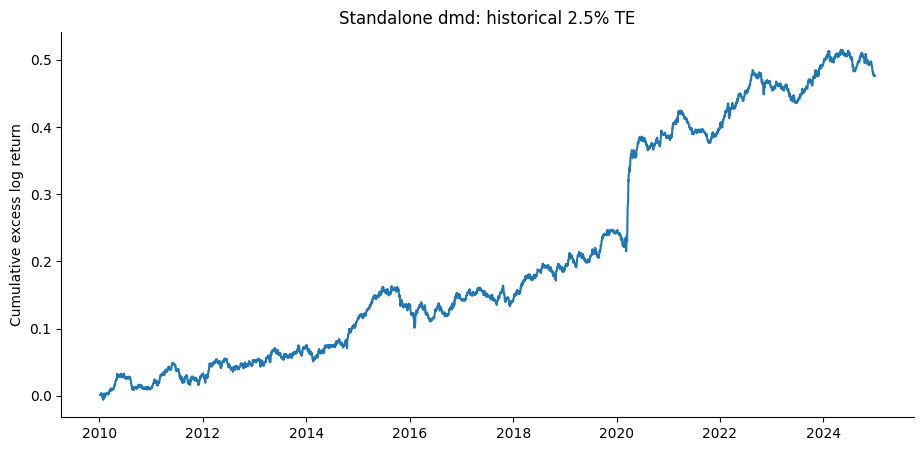

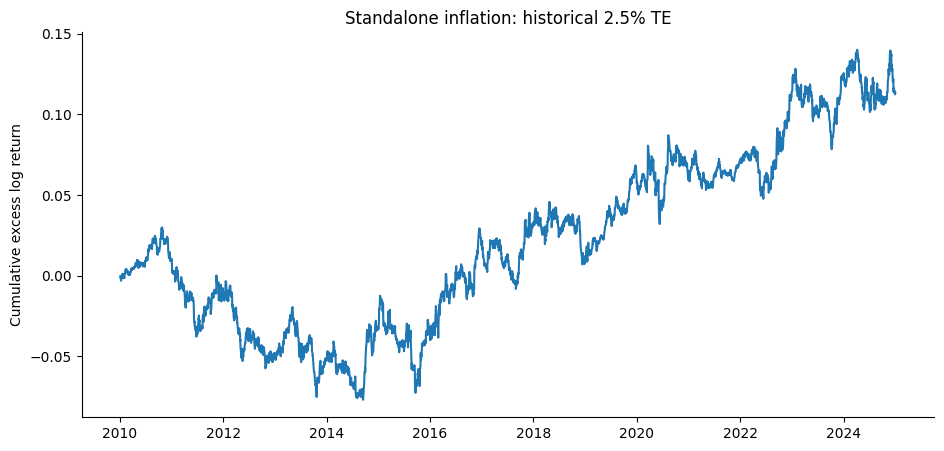

,controls,sessions,stocks,score_r2,score_correlation,raw_payoff,explained_payoff,remaining_payoff,raw_slope,adjusted_slope,payoff_share_explained
0,all,3773,2851.553406,0.015385,NaN,0.000077,3.514374e-05,0.000042,0.000087,0.000048,0.454715
1,barra,3773,2851.553406,0.003001,NaN,0.000077,1.318053e-05,0.000064,0.000087,0.000073,0.170539
2,barra_momentum,3773,2851.553406,0.002083,-0.021224,0.000077,1.237495e-05,0.000065,0.000087,0.000074,0.160116
3,barra_reversal,3773,2851.553406,0.000903,-0.005821,0.000077,7.715134e-07,0.000077,0.000087,0.000086,0.009982
4,momentum,3773,2851.553406,0.002647,NaN,0.000077,1.388677e-05,0.000063,0.000087,0.000072,0.179677
5,reversal,3773,2851.553406,0.013233,NaN,0.000077,2.441047e-05,0.000053,0.000087,0.000060,0.315840
6,sf_momentum,3773,2851.553406,0.001758,-0.017262,0.000077,9.680704e-06,0.000068,0.000087,0.000077,0.125256
7,sf_quant,3773,2851.553406,0.013920,NaN,0.000077,3.038958e-05,0.000047,0.000087,0.000054,0.393203
8,sf_reversal,3773,2851.553406,0.012431,0.106563,0.000077,2.318684e-05,0.000054,0.000087,0.000061,0.300008


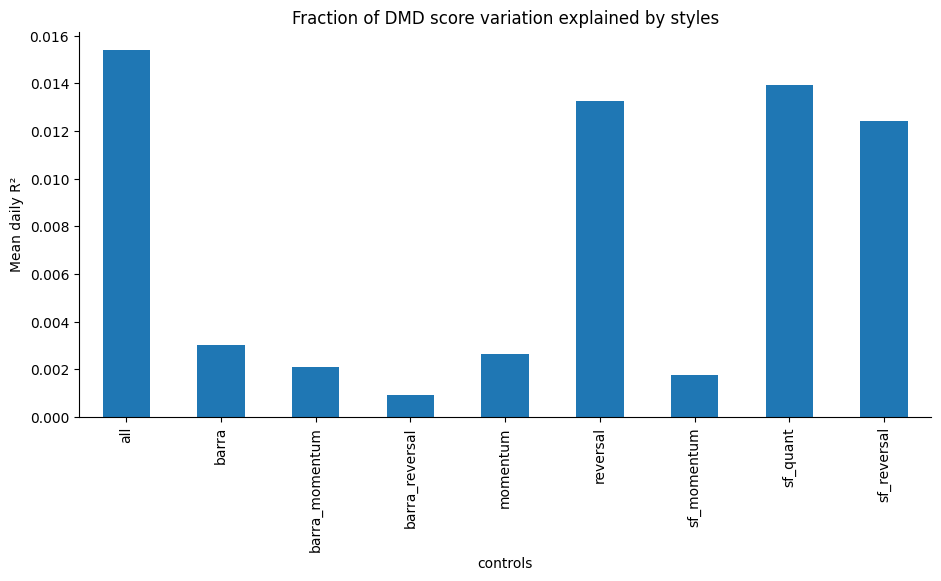

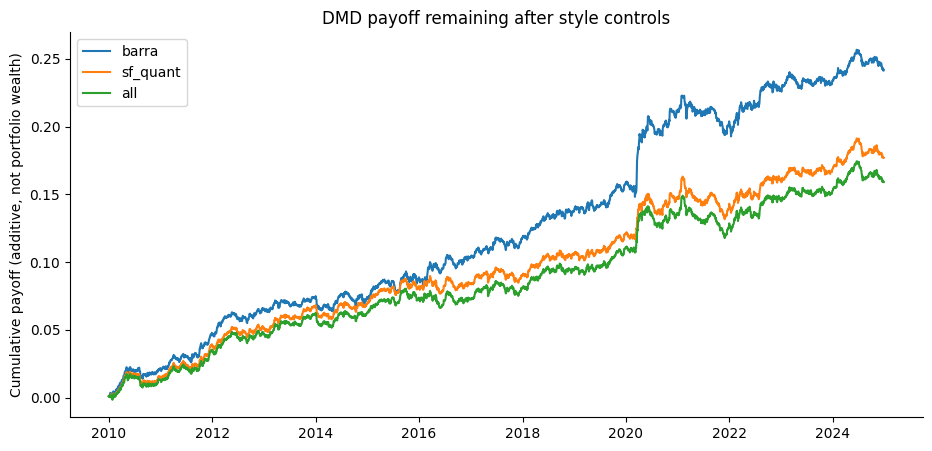

In [3]:
for variant in ['active','long_only']:
    fig, ax=plt.subplots()
    for method in ['dmd_matched_raw','dmd_residual']:
        g=r[r.portfolio==f'{method}_{variant}'].sort_values('date')
        ax.plot(g.date,(np.log1p(g.portfolio_return)-np.log1p(g.benchmark_return)).cumsum(),label=method)
    ax.set(title=f'DMD comparison: {variant} (historical 2.5% TE)',ylabel='Cumulative excess log return');ax.legend();plt.show()
for signal in ['dmd','inflation']:
    g=pd.read_parquet(DATA/f'historical_{signal}_returns.parquet').sort_values('date')
    fig,ax=plt.subplots(); ax.plot(g.date,(np.log1p(g.portfolio_return)-np.log1p(g.benchmark_return)).cumsum())
    ax.set(title=f'Standalone {signal}: historical 2.5% TE',ylabel='Cumulative excess log return');plt.show()
a=pd.read_parquet(DATA/'historical_attribution_daily.parquet')
display(pd.read_csv(DATA/'historical_attribution_summary.csv'))
fig,ax=plt.subplots();a.groupby('controls').score_r2.mean().plot.bar(ax=ax)
ax.set(title='Fraction of DMD score variation explained by styles',ylabel='Mean daily R²');plt.show()
fig,ax=plt.subplots()
for name in ['barra','sf_quant','all']:
    g=a[a.controls==name].sort_values('signal_date')
    ax.plot(g.signal_date,g.remaining_payoff.cumsum(),label=name)
ax.set(title='DMD payoff remaining after style controls',ylabel='Cumulative payoff (additive, not portfolio wealth)');ax.legend();plt.show()
